# Vehicle Fuel Economy: MLDA Coursework
Student ID: `00021943`

**Question:** Can we predict the combined fuel economy (MPG) of a car with a combustion engine from its technical characteristics, such as engine size, number of cylinders, drive type, fuel type and model year?

**How this work differs from existing solutions:** An existing Kaggle notebook on an older copy of the EPA data (1984-2017, link below) mixes electric cars with combustion-engine cars, splits the data randomly, uses only 4 features (engine size is not one of them) and reports only R². My work changes each of these. My goal is also different. That notebook tests its model on a random sample of old cars, and I want to estimate the fuel economy of new car models that are not in the data yet, for the users of the Streamlit app. The columns `city08`, `highway08` and CO2 come from the same fuel consumption test as the target (`comb08` is calculated from `city08` and `highway08`), so I remove them as leakage and use 13 technical characteristics of the car instead, including engine size (C.6). I model only cars with a combustion engine. Electric and hydrogen cars are excluded because their MPG is an MPG-equivalent (MPGe), a different unit (B.4). I also join a second file, `emissions.csv`, and check that the join does not duplicate cars (A). Instead of a random split, I test on the newest model years (2024-2027) and validate with `GroupKFold` by base model (C.7), which is closer to how the Streamlit app will be used. Section E evaluates the models with RMSE and MAE alongside R². The data is the latest official EPA release, with records updated up to September 2026.

**Data source:** U.S. Environmental Protection Agency and U.S. Department of Energy, fueleconomy.gov (U.S. government data, public domain). I downloaded `vehicles.csv` and `emissions.csv` directly from https://www.fueleconomy.gov/feg/download.shtml, not from Kaggle.

Kaggle notebook used for comparison: https://www.kaggle.com/code/ffaraz/predictive-modeling-for-mpg-estimation

In [1]:
# All libraries used in the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

RANDOM_STATE = 42  # same seed everywhere so results are reproducible

## A. Load dataset

In [2]:
# low_memory=False: read the whole file at once so pandas can detect column types correctly
vehicles = pd.read_csv("../data/raw/vehicles.csv", low_memory=False)

print(vehicles.shape)
vehicles.head()

(50407, 84)


,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
0,14.167143,0.0,0.0,0.0,19,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
1,27.046364,0.0,0.0,0.0,9,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
2,11.018889,0.0,0.0,0.0,23,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
3,27.046364,0.0,0.0,0.0,10,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
4,15.658421,0.0,0.0,0.0,17,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [3]:
vehicles.info()

<class 'pandas.DataFrame'>
RangeIndex: 50407 entries, 0 to 50406
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   barrels08        50407 non-null  float64
 1   barrelsA08       50407 non-null  float64
 2   charge120        50407 non-null  float64
 3   charge240        50407 non-null  float64
 4   city08           50407 non-null  int64  
 5   city08U          50407 non-null  float64
 6   cityA08          50407 non-null  int64  
 7   cityA08U         50407 non-null  float64
 8   cityCD           50407 non-null  float64
 9   cityE            50407 non-null  float64
 10  cityUF           50407 non-null  float64
 11  co2              50407 non-null  int64  
 12  co2A             50407 non-null  int64  
 13  co2TailpipeAGpm  50407 non-null  float64
 14  co2TailpipeGpm   50407 non-null  float64
 15  comb08           50407 non-null  int64  
 16  comb08U          50407 non-null  float64
 17  combA08          50407 

**Observations**

The dataset has 50,407 rows (one row per car configuration: model, year, engine and transmission) and 84 columns. Most columns are numbers (int64 and float64), for example engine size, cylinders and fuel consumption. 24 columns are text, such as `make`, `drive`, `trany` and `VClass`, so they will need encoding later. The `info()` output shows that some columns have empty values (for example `cylinders`, `displ` and `drive`), and some other columns probably use 0 or -1 instead of missing values, so I will check this in the EDA.

### Joining `emissions.csv`

In [4]:
emissions = pd.read_csv("../data/raw/emissions.csv")

print(emissions.shape)
print("unique car ids:", emissions["id"].nunique())

# How many emission rows does one car have?
print(emissions["id"].value_counts().value_counts())
print(emissions["score"].value_counts().sort_index())
emissions.head()

(53022, 8)
unique car ids: 25958
count
2    22066
1     1922
3     1015
4      889
5       33
6       31
9        1
7        1
Name: count, dtype: int64
score
-12.0       13
-2.0         7
 1.0      3782
 2.0      1538
 3.0      4893
 4.0       504
 5.0     19918
 6.0     13068
 7.0      5100
 8.0       638
 9.0      1337
 10.0     2224
Name: count, dtype: int64


,efid,id,salesArea,score,scoreAlt,smartwayScore,standard,stdText
0,4HNXV03.2MJE,19332,3,1.0,-1.0,-1,B9,BIN 9
1,4HNXV03.2MJE,19332,7,1.0,-1.0,-1,L1,LEV
2,4HNXV03.2MJE,19333,3,1.0,-1.0,-1,B9,BIN 9
3,4HNXV03.2MJE,19333,7,1.0,-1.0,-1,L1,LEV
4,4ADXV01.8346,19334,3,1.0,-1.0,-1,B9,BIN 9


**Observations:** `emissions.csv` has 53,022 rows but only 25,958 unique `id`s, because the same car has a separate row for each sales area and engine family (`salesArea` and `efid`). If I join it directly, many cars would appear 2 or more times in the data (up to 9 times). So first I aggregate it to one row per `id`, and then do a left join. A few rows have impossible scores (-12 and -2, while the scale is 1-10), so I treat them as missing.

In [5]:
# Scores -12 and -2 are not valid (the scale is 1-10), so replace them with NaN
emissions.loc[emissions["score"] < 1, "score"] = None

# One row per car: average emission score and best SmartWay score over all sales areas
emissions_per_car = emissions.groupby("id").agg(
    emission_score=("score", "mean"),
    smartway_score=("smartwayScore", "max"),
)

# Left join: keep every car from vehicles, even if it has no emission data
# validate="one_to_one" raises an error if the join would duplicate rows
df = vehicles.merge(emissions_per_car, on="id", how="left", validate="one_to_one")

print(df.shape)
print("cars with emission data:", df["emission_score"].notna().sum())
print(df.loc[df["emission_score"].notna(), "year"].agg(["min", "max"]))

(50407, 86)
cars with emission data: 25900
min    2004
max    2025
Name: year, dtype: int64


**Observations:** After the join, `df` still has 50,407 rows (one per car), so no rows were duplicated or lost. Only 25,900 cars (about 51%) have a valid emission score, all from model years 2004-2025, because the emissions file does not cover older cars. `smartway_score` is partly based on greenhouse gas (CO2) emissions, which are calculated from fuel consumption, so I treat it as data leakage and do not use it as a feature (C.4, C.6). The EDA in section B is done on the main `vehicles` table, and section C will start from `df`.

## B. Exploratory Data Analysis

### B.1 Statistical summary
I use `comb08` (combined MPG) as the target variable, because it is the main measure of fuel economy.

In [6]:
# Key numeric columns: target (comb08) + main features + other fuel-related columns
key_cols = ["comb08", "city08", "highway08", "displ", "cylinders", "year",
            "co2TailpipeGpm", "fuelCost08", "barrels08"]

# Statistical summary: mean, std, min/max, quartiles + variance
summary = vehicles[key_cols].describe().T
summary["variance"] = vehicles[key_cols].var()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,variance
comb08,50407.0,23.10,14.41,7.00,17.00,20.00,24.00,146.00,207.70
city08,50407.0,21.07,15.61,6.00,15.00,18.00,21.00,153.00,243.65
highway08,50407.0,26.70,13.16,9.00,20.00,24.00,29.00,142.00,173.15
displ,48754.0,3.26,1.35,0.00,2.10,3.00,4.20,8.40,1.82
cylinders,48752.0,5.69,1.77,2.00,4.00,6.00,6.00,16.00,3.14
year,50407.0,2005.53,13.15,1984.00,1993.00,2007.00,2017.00,2027.00,172.99
co2TailpipeGpm,50407.0,442.87,144.20,0.00,370.29,444.35,522.76,1269.57,20792.36
fuelCost08,50407.0,3653.17,1146.97,0.00,2900.00,3550.00,4350.00,11750.00,1315534.00
barrels08,50407.0,14.84,4.85,0.05,12.40,14.88,17.50,42.50,23.49


**Observations:** The average combined MPG is about 23, but the std is high (14.4) and the maximum is 146, which means there are some extreme values (electric cars). Engine size (`displ`) is between 0 and 8.4 litres with a mean of 3.3, and cars are from 1984 to 2027. Variance is very different between columns (e.g. 1.8 for `displ` and over 1 million for `fuelCost08`), so features will need scaling for some models.

In [7]:
# Missing values (NaN): count and percentage, only columns that have them
missing = vehicles.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(vehicles) * 100).round(1)
print(pd.DataFrame({"missing": missing, "percent": missing_pct}))

# Some columns use -1 as a "no data" code instead of NaN
for col in ["co2", "feScore", "ghgScore"]:
    print(col, "has", (vehicles[col] == -1).sum(), "rows with -1")

            missing  percent
c240bDscr     50272     99.7
c240Dscr      50266     99.7
sCharger      49240     97.7
rangeA        48397     96.0
fuelType2     48394     96.0
guzzler       47548     94.3
evMotor       46771     92.8
atvType       43547     86.4
tCharger      38620     76.6
trans_dscr    35363     70.2
startStop     31689     62.9
mfrCode       30808     61.1
eng_dscr      18436     36.6
cylinders      1655      3.3
displ          1653      3.3
drive          1186      2.4
trany            11      0.0
fuelType1         2      0.0
co2 has 31939 rows with -1
feScore has 32012 rows with -1
ghgScore has 32012 rows with -1


**Observations:** Many text columns are almost empty (e.g. `c240Dscr`, `sCharger`, `fuelType2`, `guzzler` are more than 90% missing), so most of them are not useful and can be dropped. `sCharger` is an exception: an empty value there means "no supercharger", so I use it later for a feature (C.5). `displ` and `cylinders` are missing for about 3.3% of rows; below I check which cars these are. Also, `co2`, `feScore` and `ghgScore` use -1 instead of NaN for about 32,000 rows, so these are hidden missing values that `info()` does not show.

In [8]:
# Which cars have no engine size?
print(vehicles.loc[vehicles["displ"].isna(), "fuelType1"].value_counts(dropna=False))

# Petrol cars without engine size, and cars with displ = 0, need a closer look
petrol_no_displ = vehicles["displ"].isna() & vehicles["fuelType1"].str.contains("Gasoline", na=False)
vehicles.loc[petrol_no_displ | (vehicles["displ"] == 0),
             ["make", "model", "year", "fuelType1", "displ", "cylinders"]]

fuelType1
Electricity         1607
Hydrogen              42
Regular Gasoline       2
NaN                    2
Name: count, dtype: int64


,make,model,year,fuelType1,displ,cylinders
21410,Subaru,RX Turbo,1985,Regular Gasoline,NaN,NaN
21411,Subaru,RX Turbo,1985,Regular Gasoline,NaN,NaN
28577,Mitsubishi,i-MiEV,2016,Electricity,0.0,NaN


**Observations:** Engine size is missing for 1,607 electric cars, 42 hydrogen cars and 2 Honda CR-V e-FCEV (fuel-cell cars, their `fuelType1` is also empty). This is expected, because these cars have no combustion engine. But 2 rows are normal petrol cars (Subaru RX Turbo, 1985), so this is wrong data that I will fix in section C. One car also has `displ = 0` (Mitsubishi i-MiEV); it is an electric car, so the 0 there stands for "no engine".

In [9]:
# Data types: how many columns of each type
print(vehicles.dtypes.value_counts())

# Main categorical columns
print(vehicles["fuelType1"].value_counts(dropna=False))
print(vehicles["drive"].value_counts(dropna=False))

float64    32
int64      27
str        24
bool        1
Name: count, dtype: int64
fuelType1
Regular Gasoline     31390
Premium Gasoline     15813
Electricity           1608
Diesel                1318
Midgrade Gasoline      174
Natural Gas             60
Hydrogen                42
NaN                      2
Name: count, dtype: int64
drive
Front-Wheel Drive             15913
Rear-Wheel Drive              15857
All-Wheel Drive                6811
4-Wheel or All-Wheel Drive     6645
4-Wheel Drive                  2753
NaN                            1186
Part-time 4-Wheel Drive         735
2-Wheel Drive                   507
Name: count, dtype: int64


**Observations:** The dataset has 59 numeric columns (32 float, 27 int), 24 text columns and 1 boolean. `fuelType1` is very imbalanced: almost all cars use regular (31,390) or premium (15,813) gasoline. `drive` has 7 categories plus 1,186 missing values, and some categories overlap: "All-Wheel Drive", "4-Wheel Drive" and "4-Wheel or All-Wheel Drive" are closely related (the third label mixes the first two), and "2-Wheel Drive" does not say if it is front or rear. In section C I will merge them into fewer groups (feature engineering).

### B.2 Correlation matrix

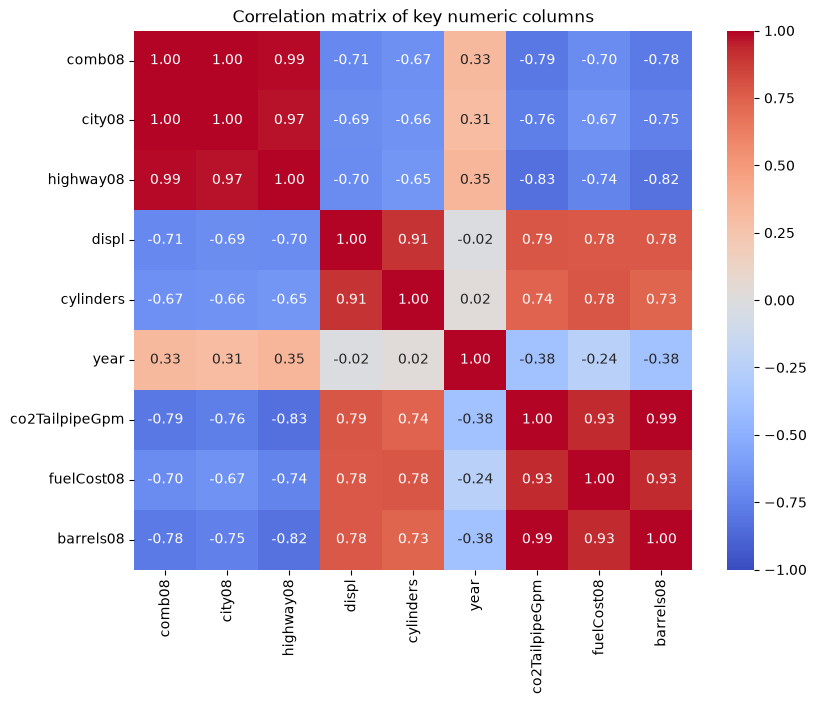

In [10]:
corr = vehicles[key_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix of key numeric columns")
plt.show()

**Observations:** `city08` and `highway08` have almost perfect correlation with `comb08` (0.99-1.00), because combined MPG is calculated from them. `co2TailpipeGpm`, `barrels08` and `fuelCost08` are also calculated from fuel consumption. These columns are data leakage, so I must remove them before training. The useful features that are left are engine size (`displ`, −0.71) and `cylinders` (−0.67): bigger engines use more fuel. `displ` and `cylinders` are also strongly correlated with each other (0.91), which matters for linear models (multicollinearity).

### B.3 Other graphs

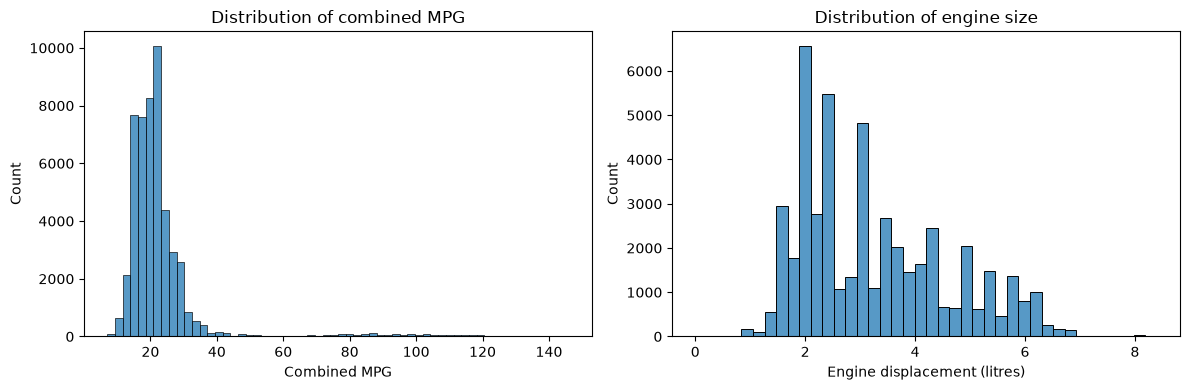

In [11]:
# Histograms of the target (combined MPG) and engine size
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(vehicles["comb08"], bins=60, ax=axes[0])
axes[0].set_title("Distribution of combined MPG")
axes[0].set_xlabel("Combined MPG")

sns.histplot(vehicles["displ"].dropna(), bins=40, ax=axes[1])
axes[1].set_title("Distribution of engine size")
axes[1].set_xlabel("Engine displacement (litres)")

plt.tight_layout()
plt.show()

**Observations:** Combined MPG is right-skewed: most cars are between 15 and 35 MPG (median 20), but there is a long tail up to 146 MPG. These very high values are electric cars (their MPG is "MPG-equivalent"), so they behave very differently from normal cars. Engine size goes from 0.6 to 8.4 litres (plus one electric car with 0), and about 62% of cars are between 2 and 4 litres.

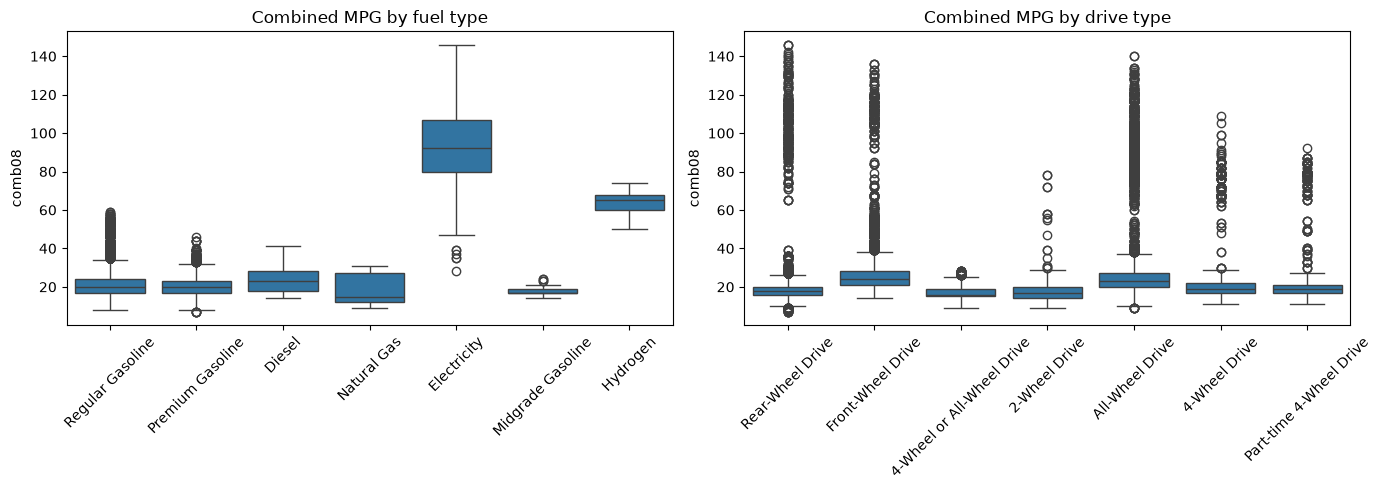

In [12]:
# Box plots: combined MPG by fuel type and by drive type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=vehicles, x="fuelType1", y="comb08", ax=axes[0])
axes[0].set_title("Combined MPG by fuel type")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=vehicles, x="drive", y="comb08", ax=axes[1])
axes[1].set_title("Combined MPG by drive type")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Observations:** Electric cars (median 92) and hydrogen cars (median 65) have much higher MPG than petrol cars (median 20), so they look like outliers compared to the other fuel types. For drive type, front-wheel drive (median 24) and all-wheel drive (23) are the most economical, while rear-wheel (18) and 4-wheel drive (19) cars are worse. The lowest medians are for the old labels "4-Wheel or All-Wheel Drive" (16) and "2-Wheel Drive" (17), which are used only for older cars. So all-wheel drive is not necessarily bad. Because the medians differ this much between categories, `fuelType1` and `drive` are useful categorical features for the model.

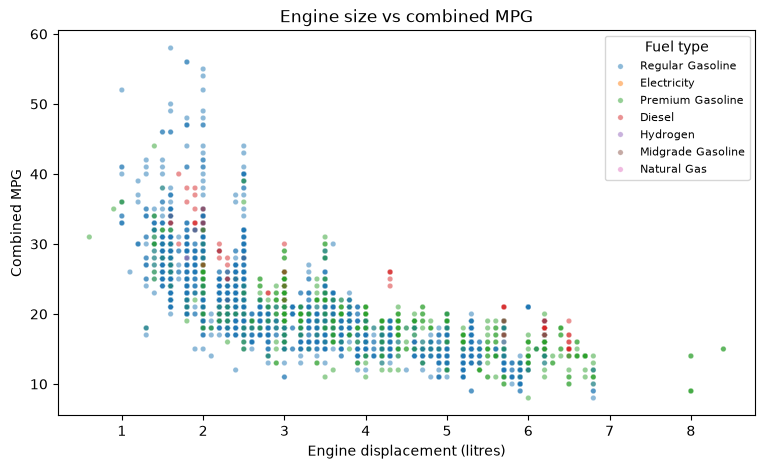

In [13]:
# Scatter plot: engine size vs combined MPG, coloured by fuel type
# take a random sample of 5000 rows so the plot is not too crowded
sample = vehicles.sample(5000, random_state=RANDOM_STATE)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample, x="displ", y="comb08", hue="fuelType1", alpha=0.5, s=15)
plt.title("Engine size vs combined MPG")
plt.xlabel("Engine displacement (litres)")
plt.ylabel("Combined MPG")
plt.legend(title="Fuel type", fontsize=8)
plt.show()

**Observations:** For petrol and diesel cars, bigger engines clearly give lower MPG, and the curve is non-linear (it flattens for big engines). This suggests that non-linear models (e.g. Random Forest) may work better than plain linear regression. Electric cars are missing from this plot because they have no engine size, so they need special handling in Data Preparation.

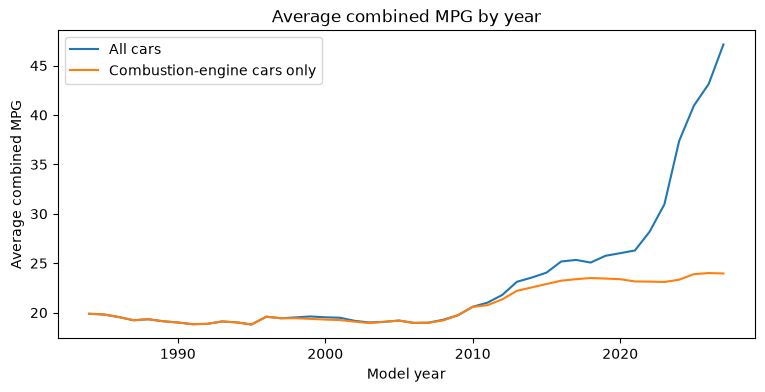

In [14]:
# Line plot: average combined MPG by year, all cars vs combustion-engine cars only
is_ice = ~vehicles["fuelType1"].isin(["Electricity", "Hydrogen"]) & vehicles["fuelType1"].notna()

plt.figure(figsize=(9, 4))
vehicles.groupby("year")["comb08"].mean().plot(label="All cars")
vehicles[is_ice].groupby("year")["comb08"].mean().plot(label="Combustion-engine cars only")
plt.title("Average combined MPG by year")
plt.xlabel("Model year")
plt.ylabel("Average combined MPG")
plt.legend()
plt.show()

**Observations:** For combustion-engine cars, the average MPG stayed at about 19 from 1984 to 2009, then grew to about 23 by 2015 and is around 24 now. For all cars the line goes much higher (about 47 in 2027), because there are more and more electric cars in recent years. So cars are becoming more economical, but a big part of the recent growth comes from EVs.

### B.4 Decision: which cars to model
The EDA shows that electric cars (1,608) and hydrogen / fuel-cell cars (44) are very different from all other cars: their `comb08` is an MPG-equivalent (median 92 and 65 vs 20 for petrol), and they have no engine size or cylinders. If I keep them, they will be strong outliers, and the main features (`displ`, `cylinders`) will be empty for them.

**Decision:** the model will predict fuel economy only for cars with a combustion engine (petrol, diesel and natural gas, including hybrids). Plug-in hybrids stay, because their `comb08` is the fuel economy in petrol mode (e.g. the 2011 Chevrolet Volt has 37 MPG in `comb08`, and its electric figure of 93 is in a separate column, `combA08`), so the unit is the same as for the other cars. The 60 natural gas cars have MPG as a gasoline equivalent, which is a small limitation. Electric and hydrogen cars will be removed in section C. This still leaves 48,755 rows, which is enough for training.

## C. Data Preparation

### C.1 Instance selection
As decided in B.4, the model is only for cars with a combustion engine, so I remove electric, hydrogen and fuel-cell cars. I work on a copy of `df` (the table with the emissions join), so the original data stays unchanged.

In [15]:
data = df.copy()

# Electric and hydrogen cars, plus 2 fuel-cell cars with empty fuelType1 (Honda CR-V e-FCEV)
no_engine = data["fuelType1"].isin(["Electricity", "Hydrogen"]) | data["fuelType1"].isna()
print("removed cars without a combustion engine:", no_engine.sum())

data = data[~no_engine]
print(data.shape)

removed cars without a combustion engine: 1652
(48755, 86)


**Observations:** 1,652 cars were removed (1,608 electric, 42 hydrogen and 2 fuel-cell cars), and 48,755 cars are left. All of them have a combustion engine, so engine size and cylinders are meaningful for every row.

### C.2 Removing duplicates

In [16]:
# Every row has its own id, so I look for rows that are the same in all other columns
duplicates = data.drop(columns="id").duplicated()
print("duplicate rows:", duplicates.sum())

data = data[~duplicates]
print(data.shape)

duplicate rows: 40
(48715, 86)


**Observations:** 40 rows were exact copies of other rows (only `id` was different), for example two identical Chrysler Sebring records. I removed them, because duplicates give some cars more weight. 48,715 rows are left. Many other cars have the same engine and transmission but are different models, so they are not duplicates and I keep them.

### C.3 Correcting wrong data

In [17]:
# 1) Impossible values: engine size and MPG must be positive
print("displ <= 0:", (data["displ"] <= 0).sum())
print("comb08 <= 0:", (data["comb08"] <= 0).sum())

# 2) Subaru RX Turbo 1985 is a petrol car, but engine size and cylinders are empty.
#    Its real engine is a 1.8-litre 4-cylinder (Subaru EA82T), so I fill it by hand
subaru = (data["make"] == "Subaru") & (data["model"] == "RX Turbo") & (data["year"] == 1985)
data.loc[subaru, ["displ", "cylinders"]] = [1.8, 4]
print(data.loc[subaru, ["make", "model", "year", "displ", "cylinders"]])

# 3) Usually highway MPG is higher than city MPG. Which cars break this rule?
city_better = data["city08"] > data["highway08"]
print("\ncity MPG > highway MPG:", city_better.sum())
print(data.loc[city_better, "atvType"].value_counts(dropna=False))

# 4) Cars that still have no cylinders, and how other Mazda rotary cars (RX-7, RX-8) are recorded
print(data.loc[data["cylinders"].isna(), ["make", "model", "year", "displ", "cylinders"]])
mazda_rotary = (data["make"] == "Mazda") & data["model"].str.startswith("RX-")
print(data.loc[mazda_rotary, "cylinders"].value_counts(dropna=False))

# All other RX-7 / RX-8 rows have cylinders = 2 (2 rotors), so the empty value is a gap in the data
rx7 = mazda_rotary & data["cylinders"].isna()
data.loc[rx7, "cylinders"] = 2
print("cylinders missing after the fix:", data["cylinders"].isna().sum())

displ <= 0: 0
comb08 <= 0: 0
         make     model  year  displ  cylinders
21410  Subaru  RX Turbo  1985    1.8        4.0
21411  Subaru  RX Turbo  1985    1.8        4.0

city MPG > highway MPG: 565
atvType
Hybrid            457
Plug-in Hybrid     98
NaN                 9
Diesel              1
Name: count, dtype: int64
        make model  year  displ  cylinders
21500  Mazda  RX-7  1986    1.3        NaN
cylinders
2.0    51
NaN     1
Name: count, dtype: int64
cylinders missing after the fix: 0


**Observations:**
- No impossible values (engine size or MPG ≤ 0) are left. The only `displ = 0` car (Mitsubishi i-MiEV) was electric and was removed in C.1.
- The Subaru RX Turbo 1985 is a petrol car with empty engine size and cylinders. I filled them with the real values from the manufacturer specification (1.8 litres, 4 cylinders), because the specification of this car is known.
- 565 cars have higher city MPG than highway MPG. This looks wrong, but almost all of them are hybrids and plug-in hybrids, which really are more economical in the city (they recover energy when braking). So this is correct data and I keep it.
- The 1986 Mazda RX-7 was the only car with empty `cylinders`. It has a rotary engine, and all other RX-7 and RX-8 rows in the data are recorded with 2 cylinders (2 rotors), so this is a gap in the data, and I filled it with 2 in the same way.
- The -1 codes in `co2`, `feScore` and `ghgScore` (found in B.1) do not need fixing, because these columns are removed as leakage in C.6.

### C.4 Missing values

In [18]:
# Missing values in the columns I plan to use
cols = ["displ", "cylinders", "drive", "trany", "tCharger", "sCharger",
        "atvType", "startStop", "emission_score", "smartway_score"]
missing = data[cols].isna().sum()
print(pd.DataFrame({"missing": missing, "percent": (missing / len(data) * 100).round(1)}))

# Only 2 cars have no transmission: too few to impute, so I remove them
data = data.dropna(subset=["trany"])
print(data.shape)

# Years of the cars with missing drive type, and of cars with missing startStop
print("drive missing, years:", data.loc[data["drive"].isna(), "year"].unique())
print("startStop missing, years:", data.loc[data["startStop"].isna(), "year"].agg(["min", "max"]).tolist())

                missing  percent
displ                 0      0.0
cylinders             0      0.0
drive              1178      2.4
trany                 2      0.0
tCharger          36935     75.8
sCharger          47548     97.6
atvType           43509     89.3
startStop         31649     65.0
emission_score    23911     49.1
smartway_score    23900     49.1
(48713, 86)
drive missing, years: [1984]
startStop missing, years: [1984, 2012]


**Observations:** I handle each column in a way that fits why its value is missing:
- `trany`: only 2 rows are missing, which is too few to be worth imputing, so I remove them (48,713 rows left).
- `drive`: 1,178 missing values, all from 1984. Removing them would delete most 1984 cars, and filling with the most common value would be a guess. So I keep them as a separate category "Unknown" (done in C.5).
- `tCharger`, `sCharger`, `atvType`: here NaN is not really missing. It means "no turbo", "no supercharger" or "no special fuel technology" (in most cases a normal petrol car), so I fill it with that meaning (C.5).
- `startStop`: missing only for cars up to 2012, when this was not reported, so it becomes "Unknown".
- `gears` (CVT cars, see C.5): filled with the median by `SimpleImputer` inside the preprocessing pipeline (C.8). The median is calculated only on the training set, so no information from the test set is used. `cylinders` has no missing values any more after the RX-7 fix in C.3.
- `emission_score` / `smartway_score`: about 49% missing (mostly cars before 2004, which the emissions file does not cover). I do not use them: imputing half a column adds a lot of guessed data, `smartway_score` is leakage (C.6), and users of the Streamlit app would not know these scores for their car.

### C.5 Feature engineering
Several raw columns are long text labels with many similar values. I turn them into simpler features that a model can use.

In [19]:
# Drive type: the labels changed over time ("4-Wheel or All-Wheel Drive" is only used until 2010)
print(data.groupby("drive")["year"].agg(["min", "max"]))

drive_map = {
    "Front-Wheel Drive": "FWD",
    "Rear-Wheel Drive": "RWD",
    "2-Wheel Drive": "RWD",  # mostly old pickups and vans, closest group is RWD
    "All-Wheel Drive": "4WD/AWD",
    "4-Wheel Drive": "4WD/AWD",
    "4-Wheel or All-Wheel Drive": "4WD/AWD",
    "Part-time 4-Wheel Drive": "4WD/AWD",
}
data["drive_group"] = data["drive"].map(drive_map).fillna("Unknown")


# Vehicle type: 34 detailed VClass labels -> 6 simple groups
def get_vehicle_type(vclass):
    vclass = vclass.lower()
    if "pickup" in vclass:
        return "Pickup"
    if "sport utility" in vclass:
        return "SUV"
    if "van" in vclass:  # vans and minivans
        return "Van"
    if "special purpose" in vclass:
        return "Special Purpose"
    if "wagon" in vclass:
        return "Station Wagon"
    return "Car"


data["vehicle_type"] = data["VClass"].apply(get_vehicle_type)


# Transmission: type and number of gears from texts like "Automatic (S8)" or "Manual 5-spd"
# CVT labels: "Automatic (variable gear ratios)" and "Automatic (AV-S6)".
# "Automatic (A1)" is NOT a CVT: it is a single-speed gearbox, used mostly by plug-in hybrids (e.g. BMW i3 REX)
def get_trans_type(trany):
    if trany.startswith("Manual"):
        return "Manual"
    if "variable" in trany or "AV" in trany:
        return "CVT"
    return "Automatic"


data["trans_type"] = data["trany"].apply(get_trans_type)
data["gears"] = data["trany"].str.extract(r"(\d+)")[0].astype(float)
data.loc[data["trans_type"] == "CVT", "gears"] = np.nan  # CVT has no real gears, filled by the imputer later

# Turbo / supercharger: NaN means the car does not have one
data["turbo"] = data["tCharger"].notna().astype(int)
data["supercharger"] = (data["sCharger"] == "S").astype(int)

# Fuel technology: empty atvType means no special technology label (in most cases a normal petrol car)
data["fuel_tech"] = data["atvType"].fillna("Standard")

# Start-stop system: not reported for older cars
data["start_stop"] = data["startStop"].fillna("Unknown")

                             min   max
drive                                 
2-Wheel Drive               1984  2006
4-Wheel Drive               1985  2027
4-Wheel or All-Wheel Drive  1984  2010
All-Wheel Drive             2009  2027
Front-Wheel Drive           1985  2027
Part-time 4-Wheel Drive     2010  2027
Rear-Wheel Drive            1984  2027


In [20]:
# Median MPG for each new feature: shows whether the new groups are useful
for col in ["drive_group", "vehicle_type", "trans_type", "fuel_tech", "start_stop"]:
    print(data.groupby(col)["comb08"].agg(["median", "count"]), "\n")

print(data["gears"].value_counts(dropna=False).sort_index())

             median  count
drive_group               
4WD/AWD        19.0  15821
FWD            24.0  15685
RWD            18.0  16029
Unknown        22.0   1178 

                 median  count
vehicle_type                  
Car                21.0  24757
Pickup             17.0   6826
SUV                20.0   9203
Special Purpose    17.0   2548
Station Wagon      22.0   3007
Van                15.0   2372 

            median  count
trans_type               
Automatic     19.0  33264
CVT           30.0   2159
Manual        21.0  13290 

                median  count
fuel_tech                    
Bifuel (CNG)      12.0     20
Bifuel (LPG)      13.5      8
CNG               14.0     50
Diesel            23.0   1245
FFV               17.0   1537
Hybrid            27.0   1899
Plug-in Hybrid    26.0    447
Standard          20.0  43507 

            median  count
start_stop               
N             22.0   8231
Unknown       19.0  31647
Y             23.0   8835 

gears
1.0        29


**Observations:** The new features clearly separate cars with different fuel economy:
- `drive_group`: FWD cars have median 24 MPG, RWD 18, 4WD/AWD 19. I had to merge AWD and 4WD because EPA changed the labels around 2009-2010: the old label "4-Wheel or All-Wheel Drive" mixes both, so it is not possible to split them for older cars. "2-Wheel Drive" was used in 1984-2006, mostly for pickups and vans (82% of these rows), which were usually rear-wheel drive, so I put them into RWD as the closest group. This is an assumption, because the label itself does not say front or rear.
- `vehicle_type`: 34 detailed `VClass` labels (some with different spellings, e.g. "Standard Pickup Trucks/2wd" and "Standard Pickup Trucks 2WD") are grouped into 6 types. Vans have median 15 MPG and cars 21.
- `trans_type` and `gears`: extracted from 39 different `trany` texts. CVT cars have median 30 MPG, compared with 19 for automatic.
- `turbo`, `supercharger`, `fuel_tech`: hybrids have median 27 MPG, compared with 20 for standard cars.

### C.6 Target and leakage columns
The target is `comb08` (combined MPG). As features I keep only the technical characteristics of the car, which are known before its fuel economy is tested. All other columns are removed:

- **Data leakage** (calculated from the measured fuel consumption, so they would give the answer to the model): `city08`, `highway08` and all their versions (`city08U`, `UCity`, `cityA08`, `highwayA08`, `combA08`, ...), `co2`, `co2TailpipeGpm`, `barrels08`, `fuelCost08`, `youSaveSpend`, `feScore`, `ghgScore`, `smartway_score`. B.2 showed that some of them have correlation 0.99-1.00 with the target.
- **Electric-part columns** (`range`, `phevComb`, `charge240`, ...): they describe the battery side of plug-in hybrids, so they have values almost only for the 447 plug-in hybrids (about 1% of the cars) and are 0 or empty for the other 99%. A feature that only means something for 1% of the data is not worth adding. `evMotor` is also filled for most normal hybrids (81%) and `rangeA` for flex-fuel and bifuel cars, but `evMotor` is a free-text battery description (e.g. "288V Ni-MH") and `rangeA` is the driving range on the second fuel, and the hybrid and flex-fuel information is already in `fuel_tech` (C.5).
- **Identifiers and dates** (`id`, `model`, `baseModel`, `engId`, `createdOn`, `modifiedOn`): they do not describe the car's technology. `model` has thousands of unique values, so the model would only memorise names.
- **Raw columns replaced by new features** in C.5: `drive`, `VClass`, `trany`, `tCharger`, `sCharger`, `atvType`, `startStop`.
- **`emission_score`**: explained in C.4.

In [21]:
target = "comb08"
num_features = ["year", "displ", "cylinders", "gears"]
bin_features = ["turbo", "supercharger"]
cat_features = ["make", "fuelType1", "drive_group", "vehicle_type", "trans_type", "fuel_tech", "start_stop"]

X = data[num_features + bin_features + cat_features]
y = data[target]
print("X:", X.shape, " y:", y.shape)

X: (48713, 13)  y: (48713,)


### C.7 Train / test split

In [22]:
# Time-based split: train on older models, test on the newest model years.
# The test set is used only once, in section E
TEST_FROM_YEAR = 2024
train_mask = X["year"] < TEST_FROM_YEAR

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print("train:", X_train.shape, "years", X_train["year"].min(), "-", X_train["year"].max())
print("test: ", X_test.shape, "years", X_test["year"].min(), "-", X_test["year"].max())
print("mean MPG  train: %.2f  test: %.2f" % (y_train.mean(), y_test.mean()))
print("mean MPG  train, only 2018-2023: %.2f" % y_train[X_train["year"] >= 2018].mean())

# Validation: 5-fold cross-validation on the training set (used for tuning in section D).
# GroupKFold keeps all years of the same base model (e.g. every Camry) in one fold,
# so CV does not test the model on a car it has already seen. In section D the groups
# must be passed to fit(), e.g. search.fit(X_train, y_train, groups=groups_train)
groups_train = data.loc[train_mask, "baseModel"]
cv = GroupKFold(n_splits=5)
print("base models in train:", groups_train.nunique())

# How different is the test set? Share of hybrids, and test cars whose base model is also in train
is_hybrid = X["fuel_tech"].isin(["Hybrid", "Plug-in Hybrid"])
recent_train = train_mask & (X["year"] >= 2018)
print("hybrids  train: %.1f%%  train 2018-2023: %.1f%%  test: %.1f%%"
      % (100 * is_hybrid[train_mask].mean(), 100 * is_hybrid[recent_train].mean(), 100 * is_hybrid[~train_mask].mean()))
print("test cars with a base model that is also in train: %.1f%%"
      % (100 * data.loc[~train_mask, "baseModel"].isin(groups_train).mean()))

train: (45548, 13) years 1984 - 2023
test:  (3165, 13) years 2024 - 2027
mean MPG  train: 20.53  test: 23.75
mean MPG  train, only 2018-2023: 23.29
base models in train: 1374
hybrids  train: 3.2%  train 2018-2023: 12.0%  test: 28.3%
test cars with a base model that is also in train: 95.4%


**Observations:** I split the data by model year instead of randomly. The Streamlit app will be used for new cars, so I want to check if a model trained on older cars can predict their fuel economy. The training set has 45,548 cars from 1984-2023, and the test set has 3,165 cars from 2024-2027. The split does not hide familiar car models: 95.4% of test cars have a base model that is also in train (e.g. a 2024 Camry in test and a 2023 Camry in train). It checks how the model works on future cars. First, every test car has a `year` outside the training range, so the model has to extrapolate. Second, the cars themselves change: hybrids and plug-in hybrids are 28.3% of the test set, but only 3.2% of train (12.0% in 2018-2023). The average MPG is higher in test (23.75) than in train (20.53), but this is mostly because train also has the old cars from 1984-2009 with about 19 MPG (B.3); for 2018-2023 the average is already 23.29, close to the test. Because of the extrapolation and the larger share of hybrids, the test error will probably be higher than with a random split, but it is a more honest estimate for the app. For validation I use `GroupKFold` with 5 folds on the training set: all years of the same base model (1,374 in train) stay in one fold, so cross-validation never checks the model on a car it has already seen. Cross-validation and the test set check different things: `GroupKFold` hides whole base models but mixes the years, while the test set has mostly familiar base models from future years. So I do not expect the two errors to be equal, and I use cross-validation only to compare and tune the models. The test set is used only once, in section E.

### C.8 Encoding and scaling
- **Numeric** (`year`, `displ`, `cylinders`, `gears`): fill missing values with the median, then `StandardScaler`.
- **Binary** (`turbo`, `supercharger`): already 0/1, kept as they are.
- **Categorical**: `OneHotEncoder`, because the categories have no natural order (e.g. FWD is not "more" than RWD), so label encoding would add a false order.

In [23]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # fills gears for CVT cars
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("bin", "passthrough", bin_features),  # already 0/1, no scaling needed
    # categories with fewer than 20 training cars (mostly rare makes) go into one "infrequent" column;
    # an unknown make in the app also goes there instead of raising an error
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False),
     cat_features),
])

# Fit only on the training set, so no information from the test set leaks into preprocessing
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print("train:", X_train_prep.shape, "test:", X_test_prep.shape)

# Check scaling: numeric columns should now have mean 0 and std 1 on the training set
pd.DataFrame(X_train_prep[:, :4], columns=num_features).describe().loc[["mean", "std"]].round(2)

train: (45548, 98) test: (3165, 98)


,year,displ,cylinders,gears
mean,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0


**Observations:** After preprocessing, the training set has 98 columns: 4 scaled numeric, 2 binary and 92 one-hot columns. The numeric columns now have mean 0 and std 1. Scaling is needed for models that use distances or penalised coefficients (KNN, SVR, Ridge), because otherwise `year` (around 2000) would dominate `displ` (around 3). Plain Linear Regression and tree models do not need scaling, but it does not hurt them, so I use the same preprocessing for all models. In every categorical column, categories with fewer than 20 cars in the training set are grouped into one "infrequent" column (in practice rare makes, and the "Bifuel (LPG)" fuel technology), which keeps the number of columns small. In section D, `preprocessor` will be put into a `Pipeline` together with each model, so that in cross-validation it is fitted again on each training fold.

## D. Model Training

## E. Model Evaluation

## Conclusion